In [36]:
import yake
import os

In [37]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [38]:
# Lister les Fichiers
data_path = "../../data/txt/"
files = [f for f in os.listdir(data_path) if f.endswith('.txt')]

In [39]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\daphd\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [40]:
# Choisir un fichier
this_file = files[6436:6536]
this_file

['KB_JB838_1956-01-10_01-00009.txt',
 'KB_JB838_1956-01-22_01-00013.txt',
 'KB_JB838_1956-01-31_01-00007.txt',
 'KB_JB838_1956-02-01_01-00009.txt',
 'KB_JB838_1956-02-15_01-00007.txt',
 'KB_JB838_1956-02-19_01-00001.txt',
 'KB_JB838_1956-02-21_01-00014.txt',
 'KB_JB838_1956-02-22_01-00010.txt',
 'KB_JB838_1956-02-25_01-00016.txt',
 'KB_JB838_1956-02-25_01-00018.txt',
 'KB_JB838_1956-02-26_01-00007.txt',
 'KB_JB838_1956-02-27_01-00004.txt',
 'KB_JB838_1956-02-28_01-00004.txt',
 'KB_JB838_1956-02-29_01-00004.txt',
 'KB_JB838_1956-02-29_01-00008.txt',
 'KB_JB838_1956-03-01_01-00016.txt',
 'KB_JB838_1956-03-03_01-00019.txt',
 'KB_JB838_1956-03-20_01-00008.txt',
 'KB_JB838_1956-03-20_01-00009.txt',
 'KB_JB838_1956-03-21_01-00010.txt',
 'KB_JB838_1956-03-25_01-00018.txt',
 'KB_JB838_1956-03-27_01-00008.txt',
 'KB_JB838_1956-03-31_01-00003.txt',
 'KB_JB838_1956-04-05_01-00011.txt',
 'KB_JB838_1956-04-08_01-00018.txt',
 'KB_JB838_1956-04-14_01-00018.txt',
 'KB_JB838_1956-04-17_01-00015.txt',
 

In [41]:
for this_file in files[6436:6536]:
    chemin = os.path.join(data_path, this_file)

    with open(chemin, "r", encoding="utf-8") as fichier:
        text = fichier.read()

    print(this_file)
    print(text[:500])

KB_JB838_1956-01-10_01-00009.txt
9 MARDI 10 JANVIER 1956 LE SOIR BOURSE D’ANVERS LUNDI j) JANVIER 1950 Tendance satisfaisante dans un marché relativement actif, mal» freiné par lea opérations de compensation. La plupart ries valeurs te contentent de confirmer leurs cotations. Quelques unes notamment la Brazllian Traction, Kuala et Royal Dulch améliorent leur cours. Les crupl- /lércs caoutchoutlères, électricités et diverses légèrement mieux. Les banques, métallurgiques et pétrolières soutenues. Les coloniales et étrangères légè
KB_JB838_1956-01-22_01-00013.txt
k DIMANCHE 22 JANVIER 1956 am NoUIre* J*etue« BEECKMAN i Anderleoht, avenue é« i;, , c Vu, 12 (Kl- 21.48.66) et Gcor- ^“"noSMANS, à Leeuw-Salni-Pterre *”u«u)? chausaio do Itulsbroek, ( '' l- ..n!lf 2 26 8 l»nvler 1956. à 15 h., en la W JJ“ Ventes par Notaires fl Brti- salle A ", Nnrrl, 23. vente publique de X« l,c! \mMMllNE D’ANDERLECHT MAISON de commerce et de Rapport avec Atelier C .«site de Mons, 503, façade 6 m dje t „ rp ne 

In [42]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('TOLIERS RIVEURS AJUSTEURS', np.float64(0.0024228524414769653)),
 ('RIVEURS AJUSTEURS MONTEURS', np.float64(0.00262901833591061)),
 ('GALVANOPLASTIE SABLEUR', np.float64(0.004844609821953248)),
 ('RIVEURS AJUSTEURS', np.float64(0.004912969318580831)),
 ('Tél', np.float64(0.005413810654827588)),
 ('DEM', np.float64(0.006292374723258407)),
 ('rue', np.float64(0.008772629661761396)),
 ('BRUXELLES', np.float64(0.020023977119540855)),
 ('demande', np.float64(0.0210013203231793)),
 ('Rossel', np.float64(0.028490552774363204)),
 ('remettre', np.float64(0.03189499068335585)),
 ('TOLIERS RIVEURS', np.float64(0.03347834966541813)),
 ('prés', np.float64(0.03609320898301537)),
 ('AJUSTEURS MONTEURS', np.float64(0.03623735833709573)),
 ('Chartreux', np.float64(0.03810866935041412)),
 ('bon', np.float64(0.039241068266932994)),
 ('DAMES BRUXELLES dem', np.float64(0.040309415045342877)),
 ('Chartreux BOURSE', np.float64(0.042448907027663574)),
 ('Ecrire', np.float64(0.047535196949513144)),
 ('CAFE',

In [43]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['GALVANOPLASTIE SABLEUR',
 'RIVEURS AJUSTEURS',
 'TOLIERS RIVEURS',
 'AJUSTEURS MONTEURS',
 'Chartreux BOURSE',
 'TAVERNE DEM',
 'Bons salaires',
 'BRUXELLES dem',
 'cherche place',
 'bon salaire',
 'CAFE dem']

In [44]:
for f in sorted(files)[6436:6536]:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1956-01-10_01-00009.txt mentions these keywords: Congo Belge, Rio Tinto, Brazllian Traction, Programme National, Radio scolaire, Royal Dutch, Musique belge, Industries textiles...
KB_JB838_1956-01-22_01-00013.txt mentions these keywords: vente publique, notaire MARCHANT, Notaire VAN, rue Jules, notaire vendeur...
KB_JB838_1956-01-31_01-00007.txt mentions these keywords: Vande Weyer, Van Gool, profité d'une, bat Adant, White Star, Uccle Sport...
KB_JB838_1956-02-01_01-00009.txt mentions these keywords: Régates Internationales, Grands Prix, Per irêi, Van Genechten, Van Huele, Tour d’Italie, Hollandais Van, lundi soir, prochain Tour, Anciens III, Van Vliet, Amicale Gand...
KB_JB838_1956-02-15_01-00007.txt mentions these keywords: langue russe, LITTÉRATURES SOVIÉTIQUES, Alexis CURVERS, lettres soviétiques, André ROUSSEAUX, Jean ROUSSELOT, d’un livre, Carlo Bronne, soviétique russe...
KB_JB838_1956-02-19_01-00001.txt mentions these keywords: JOURNAL QUOTIDIEN, parti communiste, Pro

In [45]:
# Stopwords (Idem que dans s1) # Choisir une année
#s'assurer que les années soient présentes dans les fichiers grâce au titre de l'article 
year = 1956
#ajout des mots pour gagner en pertinence 
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem","etc","tel","tél","app",
       "adr","bel","près","déjà","rem","fem","conf","réf","rem","trav","faç","référ",
       "gar","téléph","jard","prés","conf","rez","pet","bat"]
sw = set(sw)


In [46]:
# Choisir une année
#s'assurer que les années soient présentes dans les fichiers grâce au titre de l'article 
year = 1956

In [47]:
# Lister les fichiers de cette année
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [48]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [49]:
# Ecrire tout le contenu dans un fichier temporaire
#tmp = temporaire pour récup les mots d'une année entière pour un nuage de mots
#ensemble des articles d'une année entière dans le fichier dans l'ordi
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [50]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'9 MARDI 10 JANVIER 1956 LE SOIR BOURSE D’ANVERS LUNDI j) JANVIER 1950 Tendance satisfaisante dans un marché relativement actif, mal» freiné par lea opérations de compensation. La plupart ries valeurs te contentent de confirmer leurs cotations. Quelques unes notamment la Brazllian Traction, Kuala et Royal Dulch améliorent leur cours. Les crupl- /lércs caoutchoutlères, électricités et diverses légèrement mieux. Les banques, métallurgiques et pétrolières soutenues. Les coloniales et étrangères légè'

In [51]:
#définition d'un nom de fichier > année et nom du fichier 
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text) #plus de deux caractères, pas de mots vides 
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw] #mettre en majuscule (compréhension)
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'



In [52]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1956_clean.txt!'

In [53]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'MARDI JANVIER SOIR BOURSE ANVERS LUNDI JANVIER TENDANCE SATISFAISANTE MARCHÉ RELATIVEMENT ACTIF MAL FREINÉ LEA OPÉRATIONS COMPENSATION PLUPART RIES VALEURS CONTENTENT CONFIRMER LEURS COTATIONS QUELQUES UNES NOTAMMENT BRAZLLIAN TRACTION KUALA ROYAL DULCH AMÉLIORENT COURS CRUPL LÉRCS CAOUTCHOUTLÈRES ÉLECTRICITÉS DIVERSES LÉGÈREMENT MIEUX BANQUES MÉTALLURGIQUES PÉTROLIÈRES SOUTENUES COLONIALES ÉTRANGÈRES LÉGÈREMENT FAIBLES CLÔTURE RÉGULIÈRE BANQUES SOC PORTEFEUILLE GPTREPR IMMOBILIÈRES HYPOTH HÔTEL'

In [54]:
#élément pour lancer la projection > string pour faire un split sur l'espace après
#plus compteur 
#parcourir la liste donne une idée des mots vides à retirer dans la liste de stop words du début
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 2096), ('BRUXELLES', 1257), ('ANS', 795), ('PRIX', 721), ('TRÈS', 614), ('MAISON', 570), ('BON', 547), ('PLACE', 547), ('ECRIRE', 467), ('GRAND', 463)]


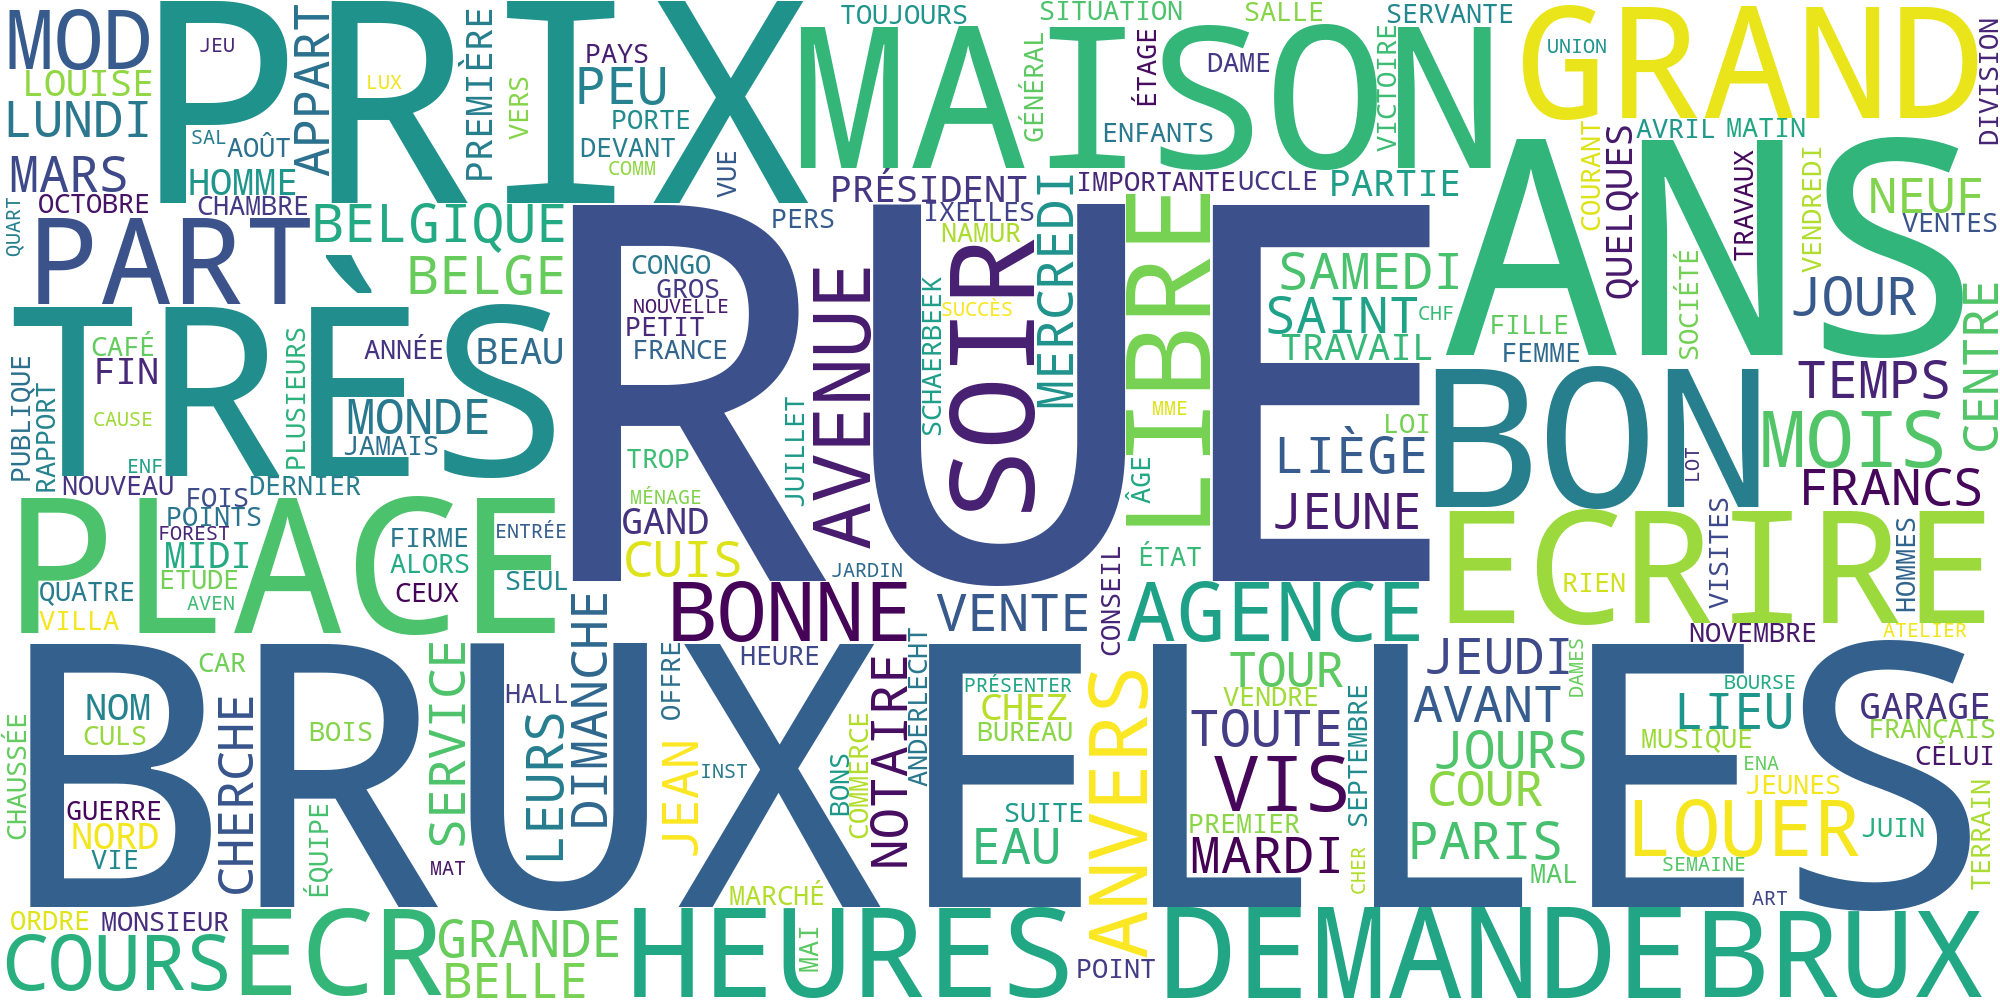

In [55]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(f"{year}.png"))
Image(filename=os.path.join(f"{year}.png"))

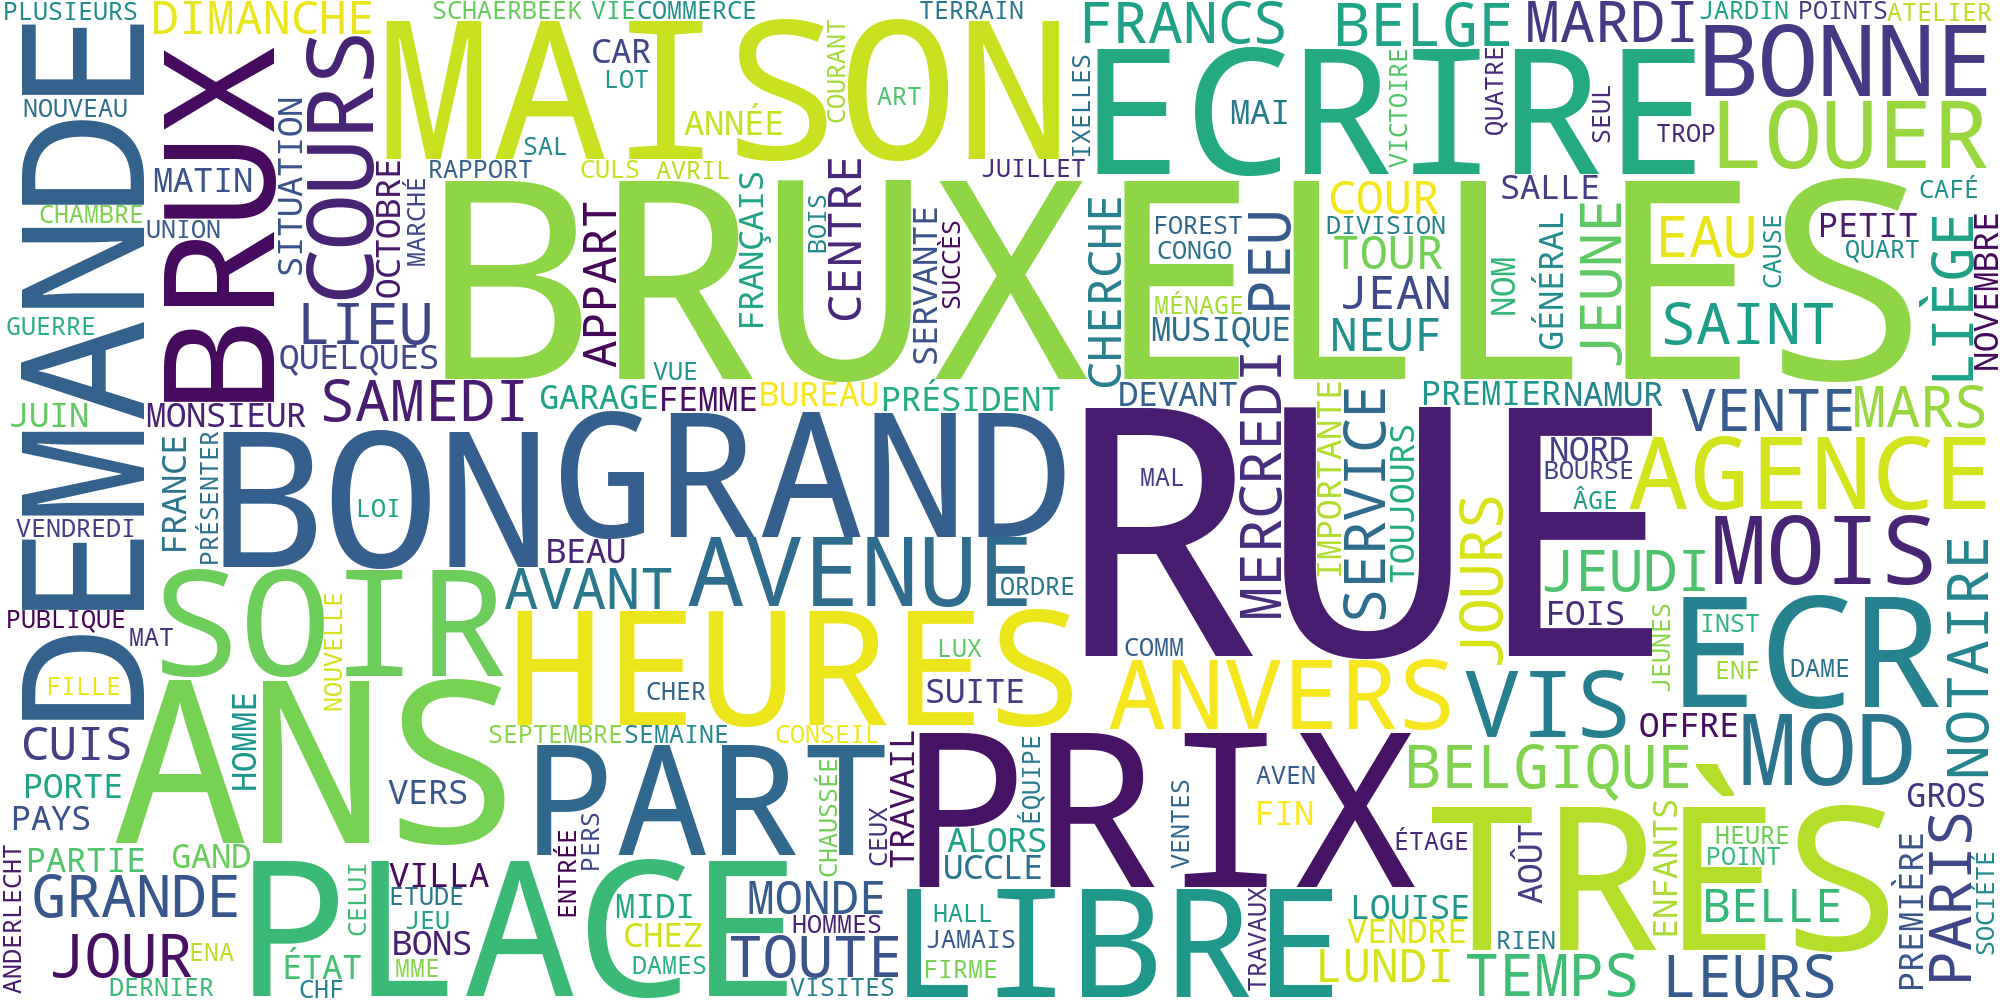

In [56]:
#nuage avec le texte clean

cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

In [62]:
from collections import defaultdict
import spacy


In [63]:
nlp = spacy.load('fr_core_news_md')
#on peut appeler nlp pour chercher des infos

In [68]:
# Charger le texte
n=1000000
text = open("../../data/tmp/1956.txt", encoding='utf-8').read()[:n]

In [69]:
%%time
# Traiter le texte

doc = nlp(text)

CPU times: total: 2min 27s
Wall time: 3min 47s


In [70]:
# Compter les entités
people = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1
# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:50]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 169 fois dans le corpus
Staline apparait 43 fois dans le corpus
Monsieur apparait 28 fois dans le corpus
Ecrire Ag apparait 23 fois dans le corpus
Desnyder apparait 21 fois dans le corpus
Agence Rossel apparait 20 fois dans le corpus
trav apparait 13 fois dans le corpus
Mac Arthur apparait 13 fois dans le corpus
Bonne apparait 12 fois dans le corpus
Louise apparait 12 fois dans le corpus
MONSIEUR apparait 12 fois dans le corpus
Roan Antelope apparait 11 fois dans le corpus
Ucele apparait 11 fois dans le corpus
Brugmann apparait 11 fois dans le corpus
- Tél apparait 11 fois dans le corpus
curr apparait 11 fois dans le corpus
Inut apparait 11 fois dans le corpus
Grandet apparait 10 fois dans le corpus
Blore apparait 10 fois dans le corpus
Madame apparait 9 fois dans le corpus
Napoléon apparait 9 fois dans le corpus
Anne apparait 9 fois dans le corpus
Mozart apparait 8 fois dans le corpus
Salle apparait 8 fois dans le corpus
Lénine apparait 8 fois dans le corpus
Acheson ap

In [71]:
# Compter les entités LOC
localisation = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "LOC" and len(ent.text) > 3:
        localisation[ent.text] += 1
# Trier et imprimer

sorted_localisation = sorted(localisation.items(), key=lambda kv: kv[1], reverse=True)

for localisation, freq in sorted_localisation[:50]:
    print(f"{localisation} apparait {freq} fois dans le corpus")

Bruxelles apparait 199 fois dans le corpus
Anvers apparait 97 fois dans le corpus
Liège apparait 77 fois dans le corpus
Brux apparait 64 fois dans le corpus
Paris apparait 53 fois dans le corpus
Gand apparait 39 fois dans le corpus
Anderlecht apparait 34 fois dans le corpus
Belgique apparait 32 fois dans le corpus
Schaerbeek apparait 30 fois dans le corpus
Téléph apparait 29 fois dans le corpus
Londres apparait 28 fois dans le corpus
Europe apparait 26 fois dans le corpus
BRUXELLES apparait 25 fois dans le corpus
Congo apparait 24 fois dans le corpus
France apparait 23 fois dans le corpus
Etat apparait 23 fois dans le corpus
Allemagne apparait 20 fois dans le corpus
Belge apparait 18 fois dans le corpus
Etats-Unis apparait 16 fois dans le corpus
Ixelles apparait 16 fois dans le corpus
Agence Rossel apparait 16 fois dans le corpus
Réunion apparait 16 fois dans le corpus
Ostende apparait 15 fois dans le corpus
Brabant apparait 15 fois dans le corpus
Etterbeek apparait 15 fois dans le cor

In [73]:
# Compter les entités ORG
organisation = defaultdict(int)
for ent in doc.ents:
    if ent.label_ == "ORG" and len(ent.text) > 3:
        organisation[ent.text] += 1
# Trier et imprimer

sorted_organisation = sorted(organisation.items(), key=lambda kv: kv[1], reverse=True)

for organisation, freq in sorted_organisation[:50]:
    print(f"{organisation} apparait {freq} fois dans le corpus")

Conseil apparait 15 fois dans le corpus
Agence Rossel apparait 13 fois dans le corpus
Royal Dutch apparait 10 fois dans le corpus
LUXEMBOURG apparait 10 fois dans le corpus
Agence Rossel num apparait 10 fois dans le corpus
Société apparait 10 fois dans le corpus
Radio scolaire apparait 8 fois dans le corpus
SUISSE apparait 7 fois dans le corpus
Chambre apparait 7 fois dans le corpus
trav apparait 7 fois dans le corpus
Conseil d'administration apparait 7 fois dans le corpus
Transports apparait 6 fois dans le corpus
Afric apparait 6 fois dans le corpus
GARAGE apparait 6 fois dans le corpus
GAND apparait 6 fois dans le corpus
FIRME apparait 6 fois dans le corpus
Agence ROSSEL apparait 6 fois dans le corpus
Firme apparait 6 fois dans le corpus
Banco apparait 5 fois dans le corpus
Congo belge apparait 5 fois dans le corpus
ANDERLECHT apparait 5 fois dans le corpus
Reuter apparait 5 fois dans le corpus
Régates Internationales apparait 5 fois dans le corpus
EUROPE apparait 5 fois dans le corp